## Segmentimi i klienteve

In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.segmentation import scale_features, rfm_quantile_segments

pd.set_option("display.float_format", "{:,.2f}".format)

rfm = pd.read_csv("../data/processed/rfm.csv", index_col="Customer ID")
print(rfm.shape)
rfm.head()

(5852, 3)


,Recency,Frequency,Monetary
Customer ID,,,
12346,326,3,"77,352.96"
12347,3,8,"4,921.53"
12348,76,5,"1,658.40"
12349,19,3,"3,678.69"
12350,311,1,294.40


In [3]:
scaled, scaler = scale_features(rfm)
scaled.describe().round(2)

,Recency_log,Frequency_log,Monetary_log
count,"5,852.00","5,852.00","5,852.00"
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-2.47,-1.06,-3.94
25%,-0.77,-1.06,-0.71
50%,0.07,-0.20,-0.04
75%,0.96,0.66,0.66
max,1.40,5.42,4.68


In [6]:
seg = rfm_quantile_segments(rfm)

for col in ["R", "F", "M"]:
    print(col, seg[col].value_counts().sort_index().to_dict())
    
seg["Segment"].value_counts()

R {1: 1171, 2: 1170, 3: 1170, 4: 1170, 5: 1171}
F {1: 1171, 2: 1170, 3: 1170, 4: 1170, 5: 1171}
M {1: 1171, 2: 1170, 3: 1170, 4: 1170, 5: 1171}


Segment
Lost               1511
Loyal              1401
Champions          1280
At risk             830
New                 447
Needs attention     383
Name: count, dtype: int64

In [7]:
profile = rfm.join(seg["Segment"]).groupby("Segment").agg(
    Klientet=("Recency", "size"),
    Recency_mediana=("Recency", "median"),
    Frequency_mediana=("Frequency", "median"),
    Monetary_mediana=("Monetary", "median"),
    Te_ardhurat=("Monetary", "sum")
)

profile["Pjesa_e_klienteve_%"] = profile["Klientet"] / profile["Klientet"].sum() * 100
profile["Pjesa_e_te_ardhuarve_%"] = profile["Te_ardhurat"] / profile["Te_ardhurat"].sum() * 100
profile.sort_values("Te_ardhurat", ascending=False).round(1)

,Klientet,Recency_mediana,Frequency_mediana,Monetary_mediana,Te_ardhurat,Pjesa_e_klienteve_%,Pjesa_e_te_ardhuarve_%
Segment,,,,,,,
Champions,1280,17.00,11.00,"3,903.90","11,602,802.40",21.90,68.00
Loyal,1401,65.00,4.00,"1,082.80","2,631,069.10",23.90,15.40
At risk,830,374.00,4.00,"1,020.50","1,597,027.20",14.20,9.40
Lost,1511,433.00,1.00,277.90,"620,553.60",25.80,3.60
New,447,27.00,1.00,366.20,"411,665.70",7.60,2.40
Needs attention,383,93.00,1.00,358.80,"205,450.00",6.50,1.20


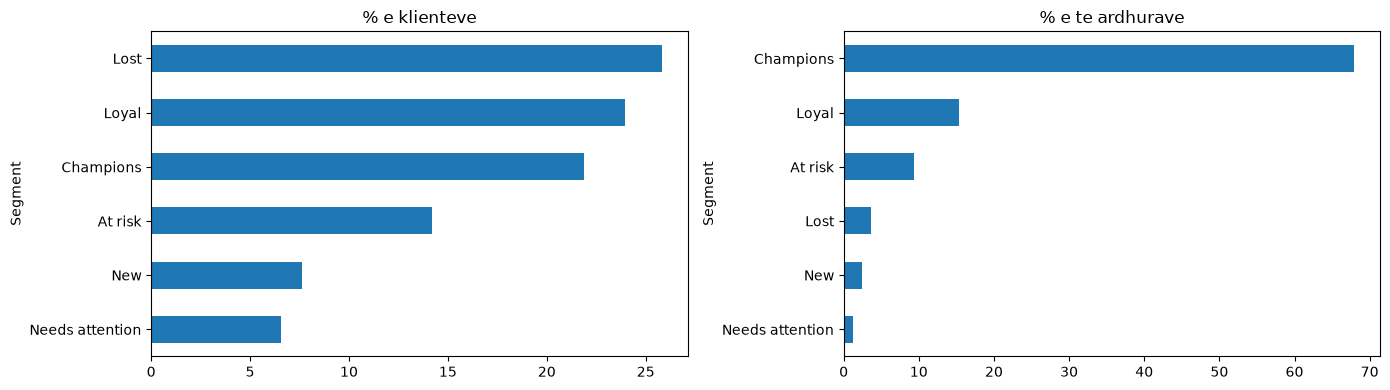

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
profile["Pjesa_e_klienteve_%"].sort_values().plot.barh(ax=axes[0], title="% e klienteve")
profile["Pjesa_e_te_ardhuarve_%"].sort_values().plot.barh(ax=axes[1], title="% e te ardhurave")
plt.tight_layout()
plt.show()

## Segmentimi baze me kuantile RFM (pike krahasimi)

Çdo klient merr pike 1-5 per Recency, Frequency dhe Monetary (kuintile), dhe pastaj nje segment sipas rregullave te thjeshta.

| Segment | Kliente | % e klienteve | % e te ardhurave | Recency (mediana, dite) | Frequency (mediana, fatura) | Monetary (mediana, £) |
|---|---|---|---|---|---|---|
| Champions | 1,280 | 21.9% | 68.0% | 17 | 11 | 3,903.90 |
| Loyal | 1,401 | 23.9% | 15.4% | 65 | 4 | 1,082.80 |
| At risk | 830 | 14.2% | 9.4% | 374 | 4 | 1,020.50 |
| Lost | 1,511 | 25.8% | 3.6% | 433 | 1 | 277.90 |
| New | 447 | 7.6% | 2.4% | 27 | 1 | 366.20 |
| Needs attention | 383 | 6.5% | 1.2% | 93 | 1 | 358.80 |

**Vezhgime**
- Champions jane 21.9% e klienteve (1,280) por sjellin 68.0% te te ardhurave. Nje klient tipik i ketij segmenti ka blere para 17 ditesh, ka 11 fatura dhe ka shpenzuar rreth 3,900 £.
- Champions dhe Loyal se bashku jane 45.8% e klienteve dhe sjellin 83.4% te te ardhurave, pra biznesi mbeshtetet te gjysma e klienteve.
- Lost jane segmenti me i madh per nga numri (25.8%) por sjellin vetem 3.6% te te ardhurave. Mediana eshte 1 fature dhe 433 dite pa bler, pra jane klient qe blen nje here dhe nuk u kthyen.
- At risk eshte segmenti me interesant per biznesin: 830 kliente me mediane 4 fatura dhe rreth 1,020 £ të shpenzuara (afer Loyal), por 374 dite pa bler. Ata kan historik blerjesh, ndaj nje fushat kthimi ka kuptim, dhe kane sjelle rreth 1.6 milion £.
- New (447 kliente) kan bler para 27 ditesh me vetem nje fature. Qellimi eshte t'i çosh te blerja e dyte.
- Kufizim: kufijt e rregullave jane vendosur me dore dhe jane te ngurte, dhe grupet e pikeve ndahen me renditje, jo me vlera te njejta. KMeans do te gjej grupe nga vet te dhenat dhe te dyja metodat do te krahasohen.

## KMeans: zgjedhja e numrit te grupeve

In [15]:
from src.segmentation import evaluate_kmeans

results = evaluate_kmeans(scaled)
results.round(3)

,inertia,silhouette
k,,
2,"8,550.16",0.44
3,"6,320.36",0.35
4,"4,881.99",0.37
5,"4,061.59",0.35
6,"3,528.96",0.34
7,"3,164.04",0.31
8,"2,879.23",0.30
9,"2,632.66",0.29
10,"2,443.11",0.29


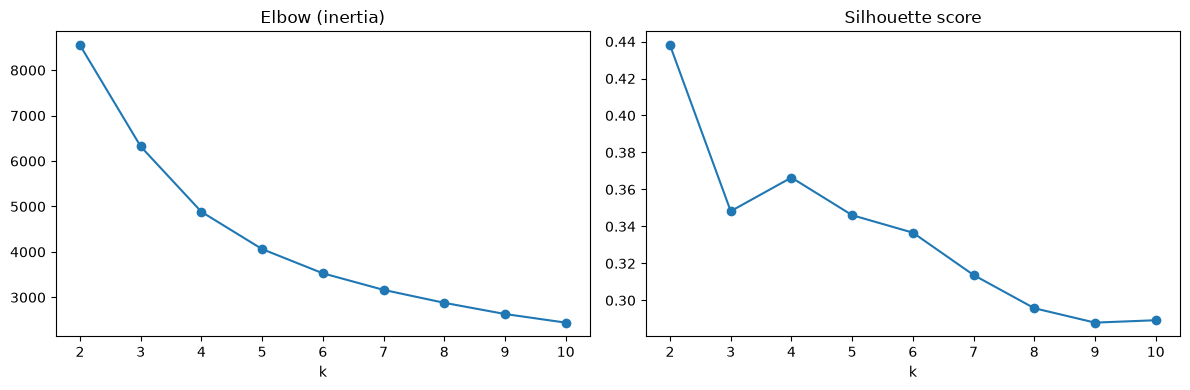

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(results.index, results["inertia"], marker="o")
axes[0].set_title("Elbow (inertia)")
axes[0].set_xlabel("k")
axes[1].plot(results.index, results["silhouette"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.cluster import KMeans

for k in [3, 4, 5]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(scaled)
    print(k, pd.Series(labels).value_counts().sort_index().to_dict())

3 {0: 1240, 1: 2373, 2: 2239}
4 {0: 1447, 1: 1260, 2: 1191, 3: 1954}
5 {0: 1635, 1: 467, 2: 1286, 3: 1129, 4: 1335}
